In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
import openpyxl

B.1  Load and Explore 

In [6]:

df = pd.read_excel("Dataset_A5.xlsx")

df = df.rename(columns={"division": "class"})

df_A = df[df["class"] == "TY-A"].copy()
df_B = df[df["class"] == "TY-B"].copy()

In [7]:
# B1: Handle missing values and determine which class is taller and heavier

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Handle missing values in required columns
required_columns = ["class", "height_cm", "height_in", "weight_kg", "weight_lb"]

df = df.dropna(subset=required_columns).copy()

# Separate classes again after removing missing values
df_A = df[df["class"] == "TY-A"].copy()
df_B = df[df["class"] == "TY-B"].copy()

# Convert measurement columns to numeric values
numeric_columns = ["height_cm", "height_in", "weight_kg", "weight_lb"]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Remove rows containing invalid or missing numeric values
df = df.dropna(subset=required_columns).copy()

# Recreate the class-specific dataframes
df_A = df[df["class"] == "TY-A"].copy()
df_B = df[df["class"] == "TY-B"].copy()

mean_height_A = df_A["height_cm"].mean()
mean_height_B = df_B["height_cm"].mean()

mean_weight_A = df_A["weight_kg"].mean()
mean_weight_B = df_B["weight_kg"].mean()

print("Average Height:")
print("TY-A:", mean_height_A)
print("TY-B:", mean_height_B)

print("\nAverage Weight:")
print("TY-A:", mean_weight_A)
print("TY-B:", mean_weight_B)

if mean_height_A > mean_height_B:
    print("\nTY-A is taller on average.")
else:
    print("\nTY-B is taller on average.")

if mean_weight_A > mean_weight_B:
    print("TY-A is heavier on average.")
else:
    print("TY-B is heavier on average.")

Missing values:
Timestamp     0
class         1
height_cm     1
height_in    11
weight_kg     1
weight_lb    14
dtype: int64
Average Height:
TY-A: 168.49960000000002
TY-B: 172.7053857142857

Average Weight:
TY-A: 60.4252
TY-B: 63.011428571428574

TY-B is taller on average.
TY-B is heavier on average.


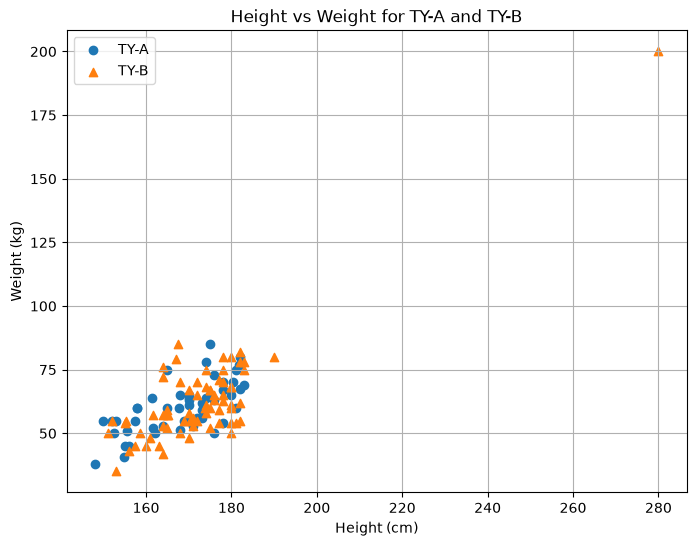

In [8]:
# B2: Plot height_cm versus weight_kg for both classes

plt.figure(figsize=(8, 6))

plt.scatter(
    df_A["height_cm"],
    df_A["weight_kg"],
    marker="o",
    label="TY-A"
)

plt.scatter(
    df_B["height_cm"],
    df_B["weight_kg"],
    marker="^",
    label="TY-B"
)

plt.title("Height vs Weight for TY-A and TY-B")
plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.legend()
plt.grid(True)
plt.show()

TY-A Correlation Matrix:


,height_cm,height_in,weight_kg,weight_lb
height_cm,1.000000,0.119917,0.675635,0.675208
height_in,0.119917,1.000000,0.053967,0.054860
weight_kg,0.675635,0.053967,1.000000,0.999723
weight_lb,0.675208,0.054860,0.999723,1.000000


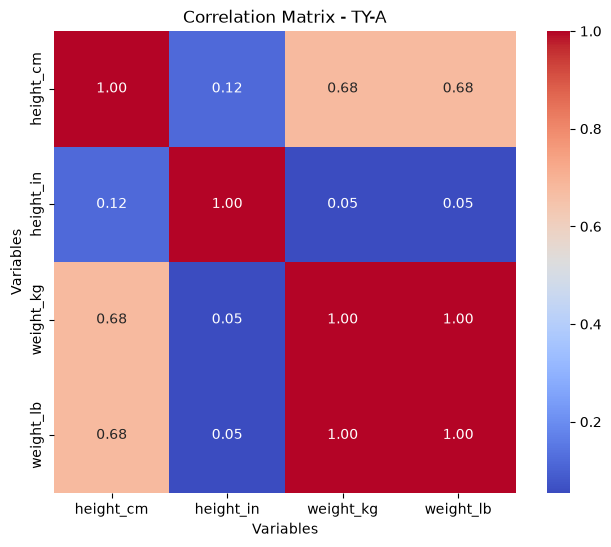

In [ ]:
# B3: Compute and visualize the correlation matrix for TY-A

columns = ["height_cm", "height_in", "weight_kg", "weight_lb"]

corr_A = df_A[columns].corr()

print("TY-A Correlation Matrix:")
display(corr_A)

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_A,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True
)

plt.title("Correlation Matrix - TY-A")
plt.xlabel("Variables")
plt.ylabel("Variables")
plt.show()


TY-B Correlation Matrix:


,height_cm,height_in,weight_kg,weight_lb
height_cm,1.000000,-0.146087,0.864292,0.793187
height_in,-0.146087,1.000000,-0.138580,-0.135383
weight_kg,0.864292,-0.138580,1.000000,0.921846
weight_lb,0.793187,-0.135383,0.921846,1.000000


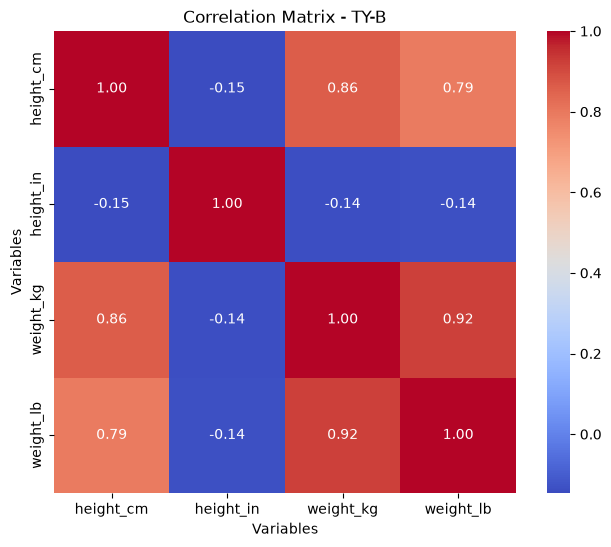

In [10]:
# B3: Compute and visualize the correlation matrix for TY-B

corr_B = df_B[columns].corr()

print("TY-B Correlation Matrix:")
display(corr_B)

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_B,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True
)

plt.title("Correlation Matrix - TY-B")
plt.xlabel("Variables")
plt.ylabel("Variables")
plt.show()

In [11]:
# B3: Test the significance of the height-weight correlation for both classes

r_A, p_A = pearsonr(df_A["height_cm"], df_A["weight_kg"])
r_B, p_B = pearsonr(df_B["height_cm"], df_B["weight_kg"])

print("TY-A:")
print("Pearson r =", r_A)
print("p-value =", p_A)

print("\nTY-B:")
print("Pearson r =", r_B)
print("p-value =", p_B)

alpha = 0.05

print("\nSignificance at 5% level:")

if p_A < alpha:
    print("TY-A: Significant")
else:
    print("TY-A: Not significant")

if p_B < alpha:
    print("TY-B: Significant")
else:
    print("TY-B: Not significant")

if abs(r_A) > abs(r_B):
    print("\nTY-A has the stronger height-weight correlation.")
else:
    print("\nTY-B has the stronger height-weight correlation.")

TY-A:
Pearson r = 0.6756347053741483
p-value = 7.322597898336775e-08

TY-B:
Pearson r = 0.8642917743868553
p-value = 5.642002143257314e-22

Significance at 5% level:
TY-A: Significant
TY-B: Significant

TY-B has the stronger height-weight correlation.


In [12]:
# B4: Implement Simple Linear Regression using the Normal Equation from scratch

def normal_equation(X, y):
    """
    Calculate beta0 and beta1 using the Normal Equation.

    X = predictor values
    y = response values
    """

    X = np.asarray(X).reshape(-1, 1)
    y = np.asarray(y).reshape(-1, 1)

    # Add column of ones for intercept
    X_design = np.c_[np.ones((X.shape[0], 1)), X]

    # Normal Equation:
    # beta = (X^T X)^(-1) X^T y
    beta = np.linalg.inv(X_design.T @ X_design) @ X_design.T @ y

    beta0 = beta[0, 0]
    beta1 = beta[1, 0]

    return beta0, beta1

In [13]:
# B4: Determine beta0 and beta1 for TY-A and TY-B

X_A = df_A["height_cm"].values
y_A = df_A["weight_kg"].values

X_B = df_B["height_cm"].values
y_B = df_B["weight_kg"].values

beta0_A, beta1_A = normal_equation(X_A, y_A)
beta0_B, beta1_B = normal_equation(X_B, y_B)

print("TY-A:")
print("Beta0 =", beta0_A)
print("Beta1 =", beta1_A)

print("\nTY-B:")
print("Beta0 =", beta0_B)
print("Beta1 =", beta1_B)

print("\nRegression equations:")
print(f"TY-A: y_hat = {beta0_A:.4f} + {beta1_A:.4f}x")
print(f"TY-B: y_hat = {beta0_B:.4f} + {beta1_B:.4f}x")

if beta1_A > beta1_B:
    print("\nTY-A has the steeper slope.")
else:
    print("\nTY-B has the steeper slope.")

TY-A:
Beta0 = -55.58646241588226
Beta1 = 0.6884981472708559

TY-B:
Beta0 = -126.73389052290416
Beta1 = 1.0986647481175646

Regression equations:
TY-A: y_hat = -55.5865 + 0.6885x
TY-B: y_hat = -126.7339 + 1.0987x

TY-B has the steeper slope.


In [14]:
# B4: Verify Normal Equation coefficients using sklearn LinearRegression

model_A = LinearRegression()
model_A.fit(X_A.reshape(-1, 1), y_A)

model_B = LinearRegression()
model_B.fit(X_B.reshape(-1, 1), y_B)

print("TY-A comparison:")
print("Normal Equation beta0:", beta0_A)
print("Sklearn beta0:", model_A.intercept_)

print("Normal Equation beta1:", beta1_A)
print("Sklearn beta1:", model_A.coef_[0])

print("\nTY-B comparison:")
print("Normal Equation beta0:", beta0_B)
print("Sklearn beta0:", model_B.intercept_)

print("Normal Equation beta1:", beta1_B)
print("Sklearn beta1:", model_B.coef_[0])

TY-A comparison:
Normal Equation beta0: -55.58646241588226
Sklearn beta0: -55.58646241587511
Normal Equation beta1: 0.6884981472708559
Sklearn beta1: 0.6884981472708249

TY-B comparison:
Normal Equation beta0: -126.73389052290416
Sklearn beta0: -126.73389052290159
Normal Equation beta1: 1.0986647481175646
Sklearn beta1: 1.0986647481175509


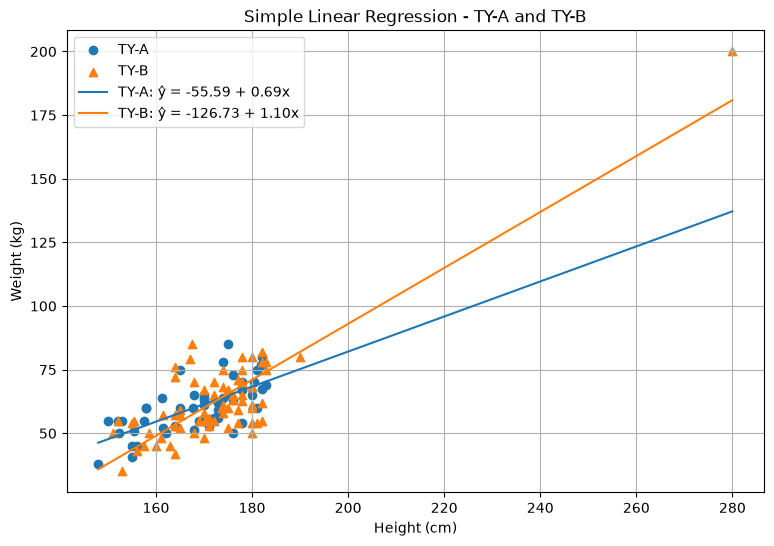

In [15]:
# B5: Plot scatter plots and fitted Normal Equation regression lines

plt.figure(figsize=(9, 6))

plt.scatter(
    df_A["height_cm"],
    df_A["weight_kg"],
    marker="o",
    label="TY-A"
)

plt.scatter(
    df_B["height_cm"],
    df_B["weight_kg"],
    marker="^",
    label="TY-B"
)

# Generate x-values for lines
x_line = np.linspace(
    df["height_cm"].min(),
    df["height_cm"].max(),
    100
)

# Predictions from Normal Equation
y_line_A = beta0_A + beta1_A * x_line
y_line_B = beta0_B + beta1_B * x_line

plt.plot(
    x_line,
    y_line_A,
    label=f"TY-A: ŷ = {beta0_A:.2f} + {beta1_A:.2f}x"
)

plt.plot(
    x_line,
    y_line_B,
    label=f"TY-B: ŷ = {beta0_B:.2f} + {beta1_B:.2f}x"
)

plt.title("Simple Linear Regression - TY-A and TY-B")
plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
# B6: Fit SGDRegressor for both classes and compare with Normal Equation

sgd_A_raw = SGDRegressor(
    max_iter=10000,
    tol=1e-8,
    learning_rate="constant",
    eta0=0.0001,
    random_state=42
)

sgd_B_raw = SGDRegressor(
    max_iter=10000,
    tol=1e-8,
    learning_rate="constant",
    eta0=0.0001,
    random_state=42
)

sgd_A_raw.fit(X_A.reshape(-1, 1), y_A)
sgd_B_raw.fit(X_B.reshape(-1, 1), y_B)

print("TY-A SGD:")
print("Intercept:", sgd_A_raw.intercept_[0])
print("Slope:", sgd_A_raw.coef_[0])

print("\nTY-B SGD:")
print("Intercept:", sgd_B_raw.intercept_[0])
print("Slope:", sgd_B_raw.coef_[0])

print("\nNormal Equation:")
print("TY-A beta0:", beta0_A)
print("TY-A beta1:", beta1_A)
print("TY-B beta0:", beta0_B)
print("TY-B beta1:", beta1_B)

TY-A SGD:
Intercept: -26490047.86074321
Slope: -6954542314.437952

TY-B SGD:
Intercept: 35522534.28140937
Slope: -11169447974.701893

Normal Equation:
TY-A beta0: -55.58646241588226
TY-A beta1: 0.6884981472708559
TY-B beta0: -126.73389052290416
TY-B beta1: 1.0986647481175646


In [17]:
# B7: Fit SGDRegressor after StandardScaler and recover original-scale coefficients

# Create scalers
scaler_A = StandardScaler()
scaler_B = StandardScaler()

# Scale X
X_A_scaled = scaler_A.fit_transform(X_A.reshape(-1, 1))
X_B_scaled = scaler_B.fit_transform(X_B.reshape(-1, 1))

# Fit SGDRegressor
sgd_A = SGDRegressor(
    max_iter=10000,
    tol=1e-8,
    learning_rate="constant",
    eta0=0.01,
    random_state=42
)

sgd_B = SGDRegressor(
    max_iter=10000,
    tol=1e-8,
    learning_rate="constant",
    eta0=0.01,
    random_state=42
)

sgd_A.fit(X_A_scaled, y_A)
sgd_B.fit(X_B_scaled, y_B)

# Coefficients in scaled space
scaled_beta0_A = sgd_A.intercept_[0]
scaled_beta1_A = sgd_A.coef_[0]

scaled_beta0_B = sgd_B.intercept_[0]
scaled_beta1_B = sgd_B.coef_[0]

# Recover original-scale coefficients
# x_scaled = (x - mean) / std
#
# y = b0_scaled + b1_scaled * ((x - mean) / std)
#
# Therefore:
# beta1_original = b1_scaled / std
# beta0_original = b0_scaled - beta1_original * mean

beta1_sgd_A = scaled_beta1_A / scaler_A.scale_[0]
beta0_sgd_A = scaled_beta0_A - beta1_sgd_A * scaler_A.mean_[0]

beta1_sgd_B = scaled_beta1_B / scaler_B.scale_[0]
beta0_sgd_B = scaled_beta0_B - beta1_sgd_B * scaler_B.mean_[0]

print("TY-A:")
print("Scaled intercept:", scaled_beta0_A)
print("Scaled slope:", scaled_beta1_A)
print("Original beta0:", beta0_sgd_A)
print("Original beta1:", beta1_sgd_A)

print("\nTY-B:")
print("Scaled intercept:", scaled_beta0_B)
print("Scaled slope:", scaled_beta1_B)
print("Original beta0:", beta0_sgd_B)
print("Original beta1:", beta1_sgd_B)

print("\nNormal Equation:")
print("TY-A:", beta0_A, beta1_A)
print("TY-B:", beta0_B, beta1_B)

TY-A:
Scaled intercept: 60.52926361659815
Scaled slope: 6.8382238668316475
Original beta0: -57.42725984153628
Original beta1: 0.7000403767019887

TY-B:
Scaled intercept: 63.09407740613722
Scaled slope: 17.74444797283348
Original beta0: -133.80995196501294
Original beta1: 1.1401151652380856

Normal Equation:
TY-A: -55.58646241588226 0.6884981472708559
TY-B: -126.73389052290416 1.0986647481175646


In [18]:
# B8: Implement MAE, MSE, RMSE and R-squared from scratch using NumPy

def mae(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return np.mean(np.abs(y_true - y_pred))


def mse(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return np.mean((y_true - y_pred) ** 2)


def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))


def r_squared(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)

    return 1 - (ss_res / ss_tot)

In [19]:
# B8: Generate predictions using Normal Equation and scaled SGD models

# Normal Equation predictions
pred_NE_A = beta0_A + beta1_A * X_A
pred_NE_B = beta0_B + beta1_B * X_B

# SGD predictions using scaled X
pred_SGD_A = sgd_A.predict(X_A_scaled)
pred_SGD_B = sgd_B.predict(X_B_scaled)

print("Predictions generated successfully.")

Predictions generated successfully.


In [20]:
# B8: Calculate all four metrics for both methods and both classes

results = []

# TY-A Normal Equation
results.append([
    "TY-A",
    "Normal Equation",
    mae(y_A, pred_NE_A),
    mse(y_A, pred_NE_A),
    rmse(y_A, pred_NE_A),
    r_squared(y_A, pred_NE_A)
])

# TY-A SGD
results.append([
    "TY-A",
    "SGDRegressor",
    mae(y_A, pred_SGD_A),
    mse(y_A, pred_SGD_A),
    rmse(y_A, pred_SGD_A),
    r_squared(y_A, pred_SGD_A)
])

# TY-B Normal Equation
results.append([
    "TY-B",
    "Normal Equation",
    mae(y_B, pred_NE_B),
    mse(y_B, pred_NE_B),
    rmse(y_B, pred_NE_B),
    r_squared(y_B, pred_NE_B)
])

# TY-B SGD
results.append([
    "TY-B",
    "SGDRegressor",
    mae(y_B, pred_SGD_B),
    mse(y_B, pred_SGD_B),
    rmse(y_B, pred_SGD_B),
    r_squared(y_B, pred_SGD_B)
])

results_df = pd.DataFrame(
    results,
    columns=["Class", "Method", "MAE", "MSE", "RMSE", "R²"]
)

display(results_df.round(4))

,Class,Method,MAE,MSE,RMSE,R²
0,TY-A,Normal Equation,5.7849,53.8562,7.3387,0.4565
1,TY-A,SGDRegressor,5.8015,53.8798,7.3403,0.4562
2,TY-B,Normal Equation,7.8352,99.0278,9.9513,0.7470
3,TY-B,SGDRegressor,7.8311,99.4508,9.9725,0.7459


In [21]:
# B8: Verify R-squared values using sklearn.metrics.r2_score

print("TY-A Normal Equation R²:")
print("From scratch:", r_squared(y_A, pred_NE_A))
print("Sklearn:", r2_score(y_A, pred_NE_A))

print("\nTY-A SGDRegressor R²:")
print("From scratch:", r_squared(y_A, pred_SGD_A))
print("Sklearn:", r2_score(y_A, pred_SGD_A))

print("\nTY-B Normal Equation R²:")
print("From scratch:", r_squared(y_B, pred_NE_B))
print("Sklearn:", r2_score(y_B, pred_NE_B))

print("\nTY-B SGDRegressor R²:")
print("From scratch:", r_squared(y_B, pred_SGD_B))
print("Sklearn:", r2_score(y_B, pred_SGD_B))

TY-A Normal Equation R²:
From scratch: 0.4564822551060119
Sklearn: 0.4564822551060119

TY-A SGDRegressor R²:
From scratch: 0.4562446748262179
Sklearn: 0.4562446748262179

TY-B Normal Equation R²:
From scratch: 0.7470002712727787
Sklearn: 0.7470002712727787

TY-B SGDRegressor R²:
From scratch: 0.7459195382953874
Sklearn: 0.7459195382953874


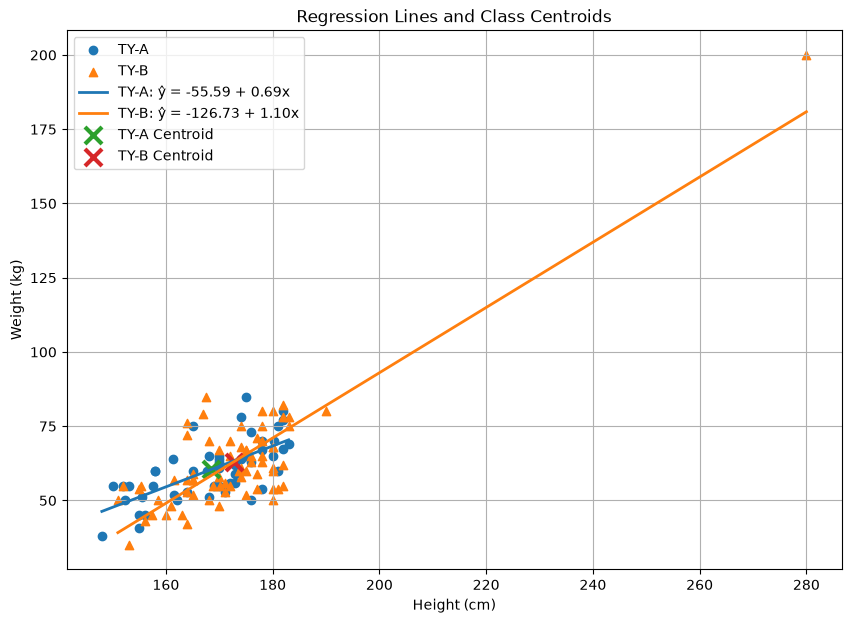

In [22]:
# B9: Plot both Normal Equation regression lines and mark class centroids

plt.figure(figsize=(10, 7))

# Scatter points
plt.scatter(
    X_A,
    y_A,
    marker="o",
    label="TY-A"
)

plt.scatter(
    X_B,
    y_B,
    marker="^",
    label="TY-B"
)

# Regression lines
x_line_A = np.linspace(X_A.min(), X_A.max(), 100)
x_line_B = np.linspace(X_B.min(), X_B.max(), 100)

y_line_A = beta0_A + beta1_A * x_line_A
y_line_B = beta0_B + beta1_B * x_line_B

plt.plot(
    x_line_A,
    y_line_A,
    linewidth=2,
    label=f"TY-A: ŷ = {beta0_A:.2f} + {beta1_A:.2f}x"
)

plt.plot(
    x_line_B,
    y_line_B,
    linewidth=2,
    label=f"TY-B: ŷ = {beta0_B:.2f} + {beta1_B:.2f}x"
)

# Centroids
centroid_A_x = np.mean(X_A)
centroid_A_y = np.mean(y_A)

centroid_B_x = np.mean(X_B)
centroid_B_y = np.mean(y_B)

plt.scatter(
    centroid_A_x,
    centroid_A_y,
    marker="x",
    s=150,
    linewidths=3,
    label="TY-A Centroid"
)

plt.scatter(
    centroid_B_x,
    centroid_B_y,
    marker="x",
    s=150,
    linewidths=3,
    label="TY-B Centroid"
)

plt.title("Regression Lines and Class Centroids")
plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.legend()
plt.grid(True)
plt.show()

In [23]:
# B10: Compare beta values, slopes and R-squared values

r2_NE_A = r_squared(y_A, pred_NE_A)
r2_SGD_A = r_squared(y_A, pred_SGD_A)

r2_NE_B = r_squared(y_B, pred_NE_B)
r2_SGD_B = r_squared(y_B, pred_SGD_B)

print("========== MODEL COMPARISON ==========")

print("\nTY-A")
print(f"Beta0 = {beta0_A:.4f}")
print(f"Beta1 = {beta1_A:.4f}")
print(f"Normal Equation R² = {r2_NE_A:.4f}")
print(f"SGDRegressor R² = {r2_SGD_A:.4f}")

print("\nTY-B")
print(f"Beta0 = {beta0_B:.4f}")
print(f"Beta1 = {beta1_B:.4f}")
print(f"Normal Equation R² = {r2_NE_B:.4f}")
print(f"SGDRegressor R² = {r2_SGD_B:.4f}")

print("\nSlope interpretation:")
print(
    f"For TY-A, an increase of 1 cm in height is associated with "
    f"an estimated increase of {beta1_A:.4f} kg in weight."
)

print(
    f"For TY-B, an increase of 1 cm in height is associated with "
    f"an estimated increase of {beta1_B:.4f} kg in weight."
)

print("\nModel reliability:")

if r2_NE_A > r2_NE_B:
    print("TY-A has the higher R², so TY-A's model provides the better fit.")
elif r2_NE_B > r2_NE_A:
    print("TY-B has the higher R², so TY-B's model provides the better fit.")
else:
    print("Both classes have the same R².")

========== MODEL COMPARISON ==========

TY-A
Beta0 = -55.5865
Beta1 = 0.6885
Normal Equation R² = 0.4565
SGDRegressor R² = 0.4562

TY-B
Beta0 = -126.7339
Beta1 = 1.0987
Normal Equation R² = 0.7470
SGDRegressor R² = 0.7459

Slope interpretation:
For TY-A, an increase of 1 cm in height is associated with an estimated increase of 0.6885 kg in weight.
For TY-B, an increase of 1 cm in height is associated with an estimated increase of 1.0987 kg in weight.

Model reliability:
TY-B has the higher R², so TY-B's model provides the better fit.


In [24]:
# B11: Apply the Normal Equation to TY-A using height_in and weight_lb

X_A_in = df_A["height_in"].values
y_A_lb = df_A["weight_lb"].values

beta0_A_in, beta1_A_in = normal_equation(
    X_A_in,
    y_A_lb
)

pred_A_lb = beta0_A_in + beta1_A_in * X_A_in

r2_A_in_lb = r_squared(
    y_A_lb,
    pred_A_lb
)

print("TY-A using height_in and weight_lb")

print(f"Beta0 = {beta0_A_in:.6f}")
print(f"Beta1 = {beta1_A_in:.6f}")
print(f"R² = {r2_A_in_lb:.6f}")

print(
    f"\nRegression equation:\n"
    f"ŷ = {beta0_A_in:.4f} + {beta1_A_in:.4f}x"
)

TY-A using height_in and weight_lb
Beta0 = 128.205808
Beta1 = 0.080935
R² = 0.003010

Regression equation:
ŷ = 128.2058 + 0.0809x
